# Hierarchical classification

**Recipe 40** · Level 4 (Advanced) · Decision type: `Choice`

Route documents through a taxonomy in stages while Python carries competing branches forward when early judgments are uncertain.

Sources:

- S02: [TypeSafe AI: Primitives (Questions)](https://docs.typesafe.ai/primitives)
- S03: [TypeSafe AI: Confidence](https://docs.typesafe.ai/confidence)
- S06: [TypeSafe AI: Cookbooks](https://docs.typesafe.ai/cookbooks)

## What you will build

A two-level taxonomy for routing a short support message: first to one of three departments (`account_billing`, `product_technical`, `people_policy`) or an explicit fallback, `unclassified`, then, inside a real department, to one of its own topics. Jev answers one narrow `Choice` at each stage; Python decides how many stages to spend. When the department answer is confident, Python commits to the single top-ranked real department and spends one further request for its topic. When it is not, Python carries the two highest-ranked real departments forward, asks a topic question for each, and picks whichever full `department.topic` path -- including the fallback, always a candidate at no request of its own -- ends up with the higher combined confidence. Either way, at least one topic request is always spent, so no document resolves in fewer than two requests. By the end you will have seen one department answer and a second one branching rescues, the composed policy that decides when to branch, and an evaluation against the two baselines this use case names: a greedy single path that never branches, and a flat classifier that asks about every full path at once.

This recipe builds on [`05-document-classification`](../05-document-classification/)'s one-stage `Choice` router and [`38-abstention-and-review-queues`](../38-abstention-and-review-queues/)'s confidence-gated review queue; it reuses both patterns rather than copying either recipe's fixtures.

## Setup and run mode

The notebook runs from its own folder with the standard library and `jev_cookbook` only. `get_backend(fixtures=...)` replays stored answers offline; setting `JEV_COOKBOOK_LIVE=1` (see the README) swaps in live calls with the same question definitions and changes nothing else. `get_backend` is called exactly once, in this cell: every request below, at every stage, reuses the one `backend` object. The header states which mode ran, and every number below carries that mode with it.

In [1]:
from jev_cookbook import get_backend, load_helpers
from jev_cookbook.evaluation import (
    accuracy,
    confusion_matrix,
    evaluate_outcomes,
    select_confidence_threshold,
    selective_curve,
)
from jev_cookbook.fixtures import load_inputs, load_labels, responses_path, select_split
from jev_cookbook.simulation import ActionLog, ReviewQueue
from jev_cookbook.style import (
    apply_style,
    plot_answer_probabilities,
    plot_confusion_matrix,
    plot_risk_coverage,
    run_header,
    show_answer,
)

apply_style()
helpers = load_helpers()  # this recipe's helpers.py, loaded by path
examples = load_inputs()
labels = load_labels()
backend = get_backend(fixtures=responses_path())  # the ONE call: every request below reuses it
# scored excludes the two demo examples: they carry no gold label, so no metric below
# is about them (see "gold label" under Evaluation).
scored = [e for e in examples if e.split not in ("train", "demo")]

offline = backend.mode in ("synthetic", "scripted")
check = " (a pipeline check, not a Jev result)" if offline else ""
# CONTRIBUTING.md section 2: a number from the validation split is a selection step, not a
# result. This label does not depend on the run mode, unlike check above: even a recorded or
# live run must not print a bare validation number.
selection = " (a selection step, not a reported result)"

# Counts actual decide() calls this notebook makes, independent of how many stored responses
# exist in fixtures/responses.json: the figure a deployed policy would spend, not a count
# derived from the fixtures themselves (see "What was and was not measured").
_requests = {"n": 0}


def decide(state, questions):
    _requests["n"] += 1
    return backend.decide(state, questions)


DEPARTMENT_QUESTION = helpers.build_department_question()
FLAT_QUESTION = helpers.build_flat_question()
TOPIC_QUESTIONS = {d: helpers.build_topic_question(d) for d in helpers.REAL_DEPARTMENTS}

run_header(
    40,
    "Hierarchical classification",
    backend=backend,
    n_examples=len(scored),
)

Recipe 40: Hierarchical classification
Mode: offline replay of synthetic fixtures, pipeline check on a fixture sample of 29 examples
Metrics in this run are checks that the pipeline works. They are not Jev results.


## The state

The state is everything Jev sees, and Python builds it. Each document in `fixtures/inputs.jsonl` carries `fields`: a document reference and its text. `build_state` passes on the text only; the reference stays in Python and is attached to every outcome below, so an identifier never passes through the model.

In [2]:
import json

demo = {e.id: e for e in examples if e.split == "demo"}
document = demo["d01-branch-rescue"]
print("Python has:")
print(json.dumps(document.fields, indent=2))
state = helpers.build_state(document.fields)
print("Jev sees:")
print(json.dumps(state, indent=2))

Python has:
{
  "doc_id": "D901",
  "text": "This cycle's totals look a bit strange to me but I can't point at one invoice -- could someone take a general look?"
}
Jev sees:
{
  "text": "This cycle's totals look a bit strange to me but I can't point at one invoice -- could someone take a general look?"
}


## The questions

Three questions, used at different stages. The first-stage question, `department`, is asked about every document: which of the three real departments should handle it, or does it not resolve to one of them at all? The fixed option set is Python's own, including the fallback this use case names ([CONTRIBUTING.md](../../CONTRIBUTING.md), section 3). The second-stage question, `topic`, depends on the first: it is asked for each real department the policy explores -- the single top-ranked one when the department answer is confident, the top two when it is not -- and is never built for `unclassified` itself, which is terminal and has no topics of its own ("Single-option Choice" in [docs/backends.md](../../docs/backends.md)). The fallback is still always a candidate in the final decision, scored directly from the department answer's own probability for it, but a topic request is always spent on at least one real department first, so it never reduces the request count by itself. The third question, `flat_topic`, is the flat baseline's: every full `department.topic` path at once, with no stages at all.

In [3]:
print(DEPARTMENT_QUESTION.instructions)
for name, description in DEPARTMENT_QUESTION.criteria.items():
    print(f"  {name}:")
    print(f"    {description}")

account_billing_topic = TOPIC_QUESTIONS[helpers.ACCOUNT_BILLING]
print()
print(account_billing_topic.instructions)
for name, description in account_billing_topic.criteria.items():
    print(f"  {name}: {description}")

print()
print(FLAT_QUESTION.instructions)
print(f"  {len(FLAT_QUESTION.criteria)} options: {list(FLAT_QUESTION.criteria)}")

Which department should handle this message?
  account_billing:
    The message is about money owed, paid, or refunded on this account: an invoice, a charge, a subscription payment, or a request for money back. A message that reports the product itself failing to work, even about a billing page, belongs to product_technical instead.
  product_technical:
    The message reports the product failing to behave as built, or asks how to use a feature: an error, a crash, a page that will not load, or a how-to question about the product. A message asking to change a charge or a subscription, with no sign anything is broken, belongs to account_billing instead.
  people_policy:
    The message is about a company policy that governs people at work: time off, leave, or workplace security requirements. It is not about this account's product or its billing at all.
  unclassified:
    The message does not resolve to one of the above: it is too vague, raises several unrelated topics at once, or is not

## One answer up close

Before any aggregate, look at one typed answer. A `Choice` answer holds the chosen option, a `probabilities` value for every option, and a `confidence`: the top probability rescaled by the number of options, `(p_max - 1/n) / (1 - 1/n)`, so it is 0 when the top option has no more than an even share and 1 when one option holds all the probability. This document is the one shown above: its department answer is genuinely torn between two real departments, with no option anywhere near a clear majority.

In [4]:
result = decide(state, {"department": DEPARTMENT_QUESTION})
answer = result["department"]
show_answer(answer)

Choice: product_technical (confidence 0.16)
  product_technical  0.37  #######
  account_billing    0.35  #######
  people_policy      0.16  ###
  unclassified       0.12  ##
Provenance: synthetic


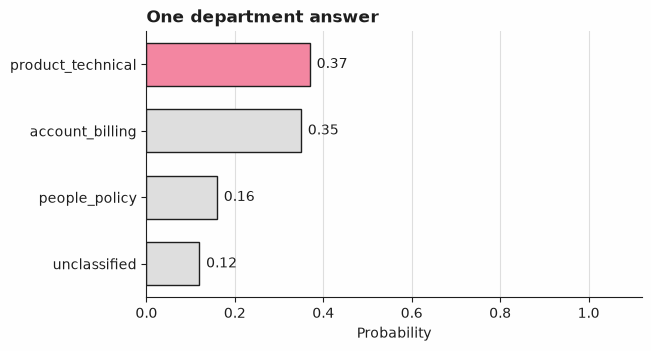

In [5]:
plot_answer_probabilities(answer, title="One department answer")

## Python's part

Jev supplies one narrow judgment at a time; the policy that decides how many stages to spend, and what to do with the result, is code, in `helpers.resolve_path` and `helpers.gate_path`. `resolve_path` asks the department question once; if its own confidence clears `branch_margin`, it commits to the single top-ranked real department and spends one further request for its topic (greedy). Otherwise it carries the top two real departments forward, asks a topic question for each, and scores every candidate full path -- including the fallback, always a candidate at no extra request of its own -- as `department_probability * topic_probability`, so a department Jev is unsure about, whose topic answer is in turn unclear, cannot win on raw department probability alone. Either way, at least one topic request is always spent, so no document resolves in fewer than two requests, including the documents (five of them here) where the department answer's own top choice is already `unclassified`: the fallback can still only win the final decision, never skip the topic request already spent on the top-ranked real department. `gate_path` then accepts the winning path as a final result only when its own composite confidence clears a second, independent [confidence gate](../../docs/glossary.md#confidence-gate), `review_gate`; anything below is sent to an explicit [review](../../docs/glossary.md#review) outcome instead. Nothing the model says can skip a stage or invent a department, because both rules live in `helpers.py` and `tests/test_helpers.py` checks them for any model answer.

Both thresholds are chosen here, on `validation`, and frozen for the rest of this notebook. `branch_margin` is chosen from the department answers alone: among `validation` documents, is the department answer's own top choice correct, and how confident is it? `select_confidence_threshold` picks the threshold that keeps the department stage single-request on as much of `validation` as the floor below requires, while that single-request subset still meets the floor's own accuracy; anything less confident than that is worth a second request to branch. `review_gate` is chosen the same way, one stage later: once every `validation` document has a resolved full path (using `branch_margin`, just frozen above), is that path's own full-path leaf correct, and how confident is it? The two documents shown next -- the one above, and a second -- demonstrate both outcomes `gate_path` can produce, and how many requests each one actually took.

In [6]:
def fetch(example, department_answer=None):
    """The three answers one document needs: the department answer (reused if already shown),
    a topic answer for each of the two real departments its own probabilities rank highest, and
    the flat baseline's own answer -- fetched once per document, never twice, however many
    times a policy below reads the result."""
    document_state = helpers.build_state(example.fields)
    if department_answer is None:
        department_answer = decide(document_state, {"department": DEPARTMENT_QUESTION})[
            "department"
        ]
    ranked = helpers.rank_real_departments(department_answer)
    topic_answers = {
        department: decide(document_state, {"topic": TOPIC_QUESTIONS[department]})["topic"]
        for department in ranked[:2]
    }
    flat_answer = decide(document_state, {"flat_topic": FLAT_QUESTION})["flat_topic"]
    return department_answer, topic_answers, flat_answer


val_examples = select_split(examples, "validation")
val_fetched = [fetch(e) for e in val_examples]
val_dept_answers = [department_answer for department_answer, _topics, _flat in val_fetched]
val_dept_gold = [helpers.department_of(labels[e.id]) for e in val_examples]
val_dept_correct = [a.choice == g for a, g in zip(val_dept_answers, val_dept_gold, strict=True)]
val_dept_confidence = [a.confidence for a in val_dept_answers]

branch_min_coverage = 0.65
print(
    f"department objective: select_confidence_threshold(..., min_coverage={branch_min_coverage:.2f})"
    f"{selection}{check}"
)
branch_margin = select_confidence_threshold(
    val_dept_correct, val_dept_confidence, min_coverage=branch_min_coverage
)
print(
    f"department accuracy on validation: "
    f"{accuracy(val_dept_gold, [a.choice for a in val_dept_answers]):.4f}{selection}{check}"
)
print(f"branch_margin, frozen from here on: {branch_margin:.4f}{selection}{check}")

val_resolved = [
    helpers.resolve_path(e.id, department_answer, topic_answers, branch_margin)
    for e, (department_answer, topic_answers, _flat) in zip(val_examples, val_fetched, strict=True)
]
val_leaf_correct = [r.leaf == labels[e.id] for e, r in zip(val_examples, val_resolved, strict=True)]
val_path_confidence = [r.path_confidence for r in val_resolved]

review_min_coverage = 0.75
print(
    f"review objective: select_confidence_threshold(..., min_coverage={review_min_coverage:.2f})"
    f"{selection}{check}"
)
review_gate = select_confidence_threshold(
    val_leaf_correct, val_path_confidence, min_coverage=review_min_coverage
)
print(
    f"full-path leaf accuracy on validation: "
    f"{sum(val_leaf_correct) / len(val_leaf_correct):.4f}{selection}{check}"
)
print(f"review_gate, frozen from here on: {review_gate:.4f}{selection}{check}")

second = demo["d02-genuinely-unclear"]
demo_resolved = []
for example, fetched in (
    (document, fetch(document, department_answer=answer)),
    (second, fetch(second)),
):
    department_answer, topic_answers, _flat = fetched
    resolved = helpers.resolve_path(example.id, department_answer, topic_answers, branch_margin)
    demo_resolved.append(resolved)
    routing = helpers.gate_path(resolved, review_gate)
    print(
        f"{example.id}: department {resolved.department}, leaf {resolved.leaf} "
        f"(path confidence {resolved.path_confidence:.4f}, {resolved.requests} requests, "
        f"branched={resolved.branched}) -> {routing.outcome} ({routing.reason}){check}"
    )

department objective: select_confidence_threshold(..., min_coverage=0.65) (a selection step, not a reported result) (a pipeline check, not a Jev result)
department accuracy on validation: 0.8571 (a selection step, not a reported result) (a pipeline check, not a Jev result)
branch_margin, frozen from here on: 0.7867 (a selection step, not a reported result) (a pipeline check, not a Jev result)
review objective: select_confidence_threshold(..., min_coverage=0.75) (a selection step, not a reported result) (a pipeline check, not a Jev result)
full-path leaf accuracy on validation: 0.9286 (a selection step, not a reported result) (a pipeline check, not a Jev result)
review_gate, frozen from here on: 0.2560 (a selection step, not a reported result) (a pipeline check, not a Jev result)
d01-branch-rescue: department account_billing, leaf account_billing.general_question (path confidence 0.2730, 3 requests, branched=True) -> answered (confident path) (a pipeline check, not a Jev result)
d02-gen

## Evaluation

Both thresholds were chosen and frozen above, on `validation`. This section reports on `test`, used once. The headline number is **leaf accuracy**: does the final predicted full path, `department.topic` (or `unclassified`), exactly match the document's [gold label](../../docs/glossary.md#gold-label)? It is reported for three policies over the identical `test` documents -- the hierarchical policy with branching, the greedy single-path baseline (the same `helpers.resolve_path`, with `branch_margin` fixed at `0.0` so it never branches), and the flat classifier that asks one combined question per document -- alongside each policy's own request count, since a cheaper policy that is just as accurate is itself a finding. Because a full path is the unit this metric compares, naming the right department for the wrong document, or the right bare topic name inside the wrong department, is never counted as correct: "the full-path trap" below shows exactly where that distinction matters on this data. [Department-level accuracy](../../docs/glossary.md#accuracy) and the full-path leaf accuracy are reported separately too, since a document can have its department right and its full path wrong, and an argmax metric over either level alone cannot see what the other level is doing. The frozen policy's own [coverage, accuracy and risk](../../docs/glossary.md#selective-prediction) -- what `gate_path` actually decided, not a plain accuracy that ignores [review](../../docs/glossary.md#review) -- closes the section, with the risk-coverage curve swept across every observed confidence. In an offline run every number here, `test` and `validation` alike, is a check that the pipeline works, and says so.

In [7]:
print(f"validation, {len(val_examples)} examples{selection}{check}")
print(
    f"leaf accuracy on validation (branching policy, used only to select thresholds): "
    f"{sum(val_leaf_correct) / len(val_leaf_correct):.4f}{selection}{check}"
)

validation, 14 examples (a selection step, not a reported result) (a pipeline check, not a Jev result)
leaf accuracy on validation (branching policy, used only to select thresholds): 0.9286 (a selection step, not a reported result) (a pipeline check, not a Jev result)


In [8]:
test_examples = select_split(examples, "test")
test_fetched = [fetch(e) for e in test_examples]
test_gold = [labels[e.id] for e in test_examples]
test_gold_department = [helpers.department_of(g) for g in test_gold]

test_resolved = [
    helpers.resolve_path(e.id, department_answer, topic_answers, branch_margin)
    for e, (department_answer, topic_answers, _flat) in zip(
        test_examples, test_fetched, strict=True
    )
]
test_greedy = [
    helpers.resolve_path(e.id, department_answer, topic_answers, 0.0)
    for e, (department_answer, topic_answers, _flat) in zip(
        test_examples, test_fetched, strict=True
    )
]
test_flat = [flat_answer.choice for _department_answer, _topic_answers, flat_answer in test_fetched]

branching_leaf = [r.leaf for r in test_resolved]
greedy_leaf = [r.leaf for r in test_greedy]
branching_requests = sum(r.requests for r in test_resolved)
greedy_requests = sum(r.requests for r in test_greedy)
flat_requests = len(test_examples)

print(
    f"test, {len(test_examples)} examples, branch_margin {branch_margin:.4f} and "
    f"review_gate {review_gate:.4f} frozen{check}"
)
print(
    f"leaf accuracy, hierarchical with branching: {accuracy(test_gold, branching_leaf):.4f}{check} "
    f"({branching_requests} requests over {len(test_examples)} documents){check}"
)
print(
    f"leaf accuracy, greedy single-path baseline: {accuracy(test_gold, greedy_leaf):.4f}{check} "
    f"({greedy_requests} requests over {len(test_examples)} documents){check}"
)
print(
    f"leaf accuracy, flat classifier baseline: {accuracy(test_gold, test_flat):.4f}{check} "
    f"({flat_requests} requests over {len(test_examples)} documents){check}"
)
print(
    f"documents where the department answer's own confidence triggered branching: "
    f"{sum(r.branched for r in test_resolved)} of {len(test_examples)}{check}"
)

all_resolved = val_resolved + test_resolved + demo_resolved
request_counts = [r.requests for r in all_resolved]
requests_distribution = {n: request_counts.count(n) for n in sorted(set(request_counts))}
print(
    f"requests actually spent per document, across all {len(all_resolved)} validation, "
    f"test and demo documents: {requests_distribution} -- every document costs at least "
    f"two requests, since a topic request is always spent on at least one real "
    f"department{check}"
)

test, 15 examples, branch_margin 0.7867 and review_gate 0.2560 frozen (a pipeline check, not a Jev result)
leaf accuracy, hierarchical with branching: 0.8667 (a pipeline check, not a Jev result) (33 requests over 15 documents) (a pipeline check, not a Jev result)
leaf accuracy, greedy single-path baseline: 0.7333 (a pipeline check, not a Jev result) (30 requests over 15 documents) (a pipeline check, not a Jev result)
leaf accuracy, flat classifier baseline: 0.8667 (a pipeline check, not a Jev result) (15 requests over 15 documents) (a pipeline check, not a Jev result)
documents where the department answer's own confidence triggered branching: 3 of 15 (a pipeline check, not a Jev result)
requests actually spent per document, across all 31 validation, test and demo documents: {2: 23, 3: 8} -- every document costs at least two requests, since a topic request is always spent on at least one real department (a pipeline check, not a Jev result)


In [9]:
branching_department = [r.department for r in test_resolved]
print(
    f"department-level accuracy (branching policy): "
    f"{accuracy(test_gold_department, branching_department):.4f}{check}"
)
flat_department = [helpers.department_of(leaf) for leaf in test_flat]
print(
    f"department-level accuracy (flat baseline): "
    f"{accuracy(test_gold_department, flat_department):.4f}{check}"
)
print(
    f"end-to-end full-path leaf accuracy (same policy): {accuracy(test_gold, branching_leaf):.4f}{check}"
)
for e, g, d, r in zip(test_examples, test_gold, test_gold_department, test_resolved, strict=True):
    if d == r.department and g != r.leaf:
        print(
            f"  {e.id}: department correct ({d}) but full path wrong: gold {g}, predicted {r.leaf}{check}"
        )

print()
print("The full-path trap: comparing bare topic names alone would hide a wrong department")
print("whenever the wrong department happens to share a topic name with the right one.")
bare_predicted = [leaf.rsplit(".", 1)[-1] for leaf in branching_leaf]
bare_gold = [leaf.rsplit(".", 1)[-1] for leaf in test_gold]
print(
    f"accuracy comparing bare topic names only (not this recipe's metric): {accuracy(bare_gold, bare_predicted):.4f}{check}"
)
print(
    f"accuracy comparing the full department.topic path (this recipe's metric): {accuracy(test_gold, branching_leaf):.4f}{check}"
)
for e, g, p, b in zip(test_examples, test_gold, branching_leaf, bare_predicted, strict=True):
    if g != p and g.rsplit(".", 1)[-1] == b:
        print(
            f"  {e.id}: full path wrong ({p} vs gold {g}) but the bare topic name alone matches ({b}){check}"
        )

department-level accuracy (branching policy): 0.9333 (a pipeline check, not a Jev result)
end-to-end full-path leaf accuracy (same policy): 0.8667 (a pipeline check, not a Jev result)
  t15-wrong-topic-right-department: department correct (account_billing) but full path wrong: gold account_billing.refund_request, predicted account_billing.invoice_question (a pipeline check, not a Jev result)

The full-path trap: comparing bare topic names alone would hide a wrong department
whenever the wrong department happens to share a topic name with the right one.
accuracy comparing bare topic names only (not this recipe's metric): 0.9333 (a pipeline check, not a Jev result)
accuracy comparing the full department.topic path (this recipe's metric): 0.8667 (a pipeline check, not a Jev result)
  t13-shared-name-trap: full path wrong (account_billing.general_question vs gold product_technical.general_question) but the bare topic name alone matches (general_question) (a pipeline check, not a Jev result

### The composed policy's own coverage, accuracy and risk

Leaf accuracy above ignores [review](../../docs/glossary.md#review) entirely, the same way a plain classification accuracy would. `gate_path`'s own decisions -- answer automatically, or send to review -- are reported with `evaluate_outcomes`, which reads what the rule actually returned rather than reapplying a confidence comparison from the outside ([docs/evaluation.md](../../docs/evaluation.md), "Outcomes versus the confidence-only view"). The risk-coverage curve sweeps `review_gate` across every observed path confidence, so the single frozen point is one place to stand on a curve, not the whole tradeoff.

task-level (hierarchical with branching, gated at review_gate): coverage 0.9333, accuracy 0.8571, risk 0.1429 (a pipeline check, not a Jev result)
risk-coverage sweep over 15 test documents (a pipeline check, not a Jev result):
  gate >= 0.8400: coverage 0.1333, accuracy 1.0000, risk 0.0000 (a pipeline check, not a Jev result)
  gate >= 0.7140: coverage 0.6667, accuracy 1.0000, risk 0.0000 (a pipeline check, not a Jev result)
  gate >= 0.6804: coverage 0.7333, accuracy 0.9091, risk 0.0909 (a pipeline check, not a Jev result)
  gate >= 0.6545: coverage 0.8000, accuracy 0.8333, risk 0.1667 (a pipeline check, not a Jev result)
  gate >= 0.2720: coverage 0.8667, accuracy 0.8462, risk 0.1538 (a pipeline check, not a Jev result)
  gate >= 0.2600: coverage 0.9333, accuracy 0.8571, risk 0.1429 (a pipeline check, not a Jev result)
  gate >= 0.2418: coverage 1.0000, accuracy 0.8667, risk 0.1333 (a pipeline check, not a Jev result)


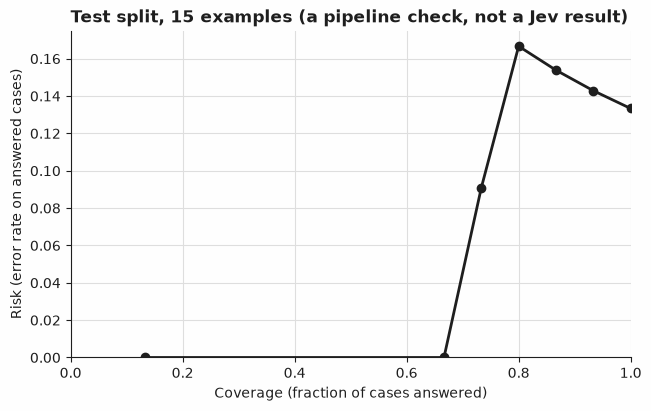

In [10]:
test_leaf_correct = [
    predicted == gold for predicted, gold in zip(branching_leaf, test_gold, strict=True)
]
test_path_confidence = [r.path_confidence for r in test_resolved]
test_routings = [helpers.gate_path(r, review_gate) for r in test_resolved]
test_accepted = [r.outcome == helpers.ANSWERED for r in test_routings]

task = evaluate_outcomes(test_accepted, test_leaf_correct)
print(
    f"task-level (hierarchical with branching, gated at review_gate): "
    f"coverage {task.coverage:.4f}, accuracy {task.accuracy:.4f}, risk {task.risk:.4f}{check}"
)

curve = selective_curve(test_leaf_correct, test_path_confidence)
print(f"risk-coverage sweep over {len(test_leaf_correct)} test documents{check}:")
for t, cov, acc, risk in zip(
    curve.thresholds, curve.coverage, curve.accuracy, curve.risk, strict=True
):
    print(f"  gate >= {t:.4f}: coverage {cov:.4f}, accuracy {acc:.4f}, risk {risk:.4f}{check}")
plot_risk_coverage(curve, title=f"Test split, {len(test_leaf_correct)} examples{check}")

Test confusion matrix (hierarchical with branching), gold rows by predicted columns (a pipeline check, not a Jev result):
  predicted ->                               account_billing.invoice_question      account_billing.refund_request    account_billing.general_question        product_technical.bug_report   product_technical.how_to_question  product_technical.general_question          people_policy.leave_policy       people_policy.security_policy                        unclassified (a pipeline check, not a Jev result)
  gold account_billing.invoice_question                                     1                                   0                                   0                                   0                                   0                                   0                                   0                                   0                                   0 (a pipeline check, not a Jev result)
  gold account_billing.refund_request                                   

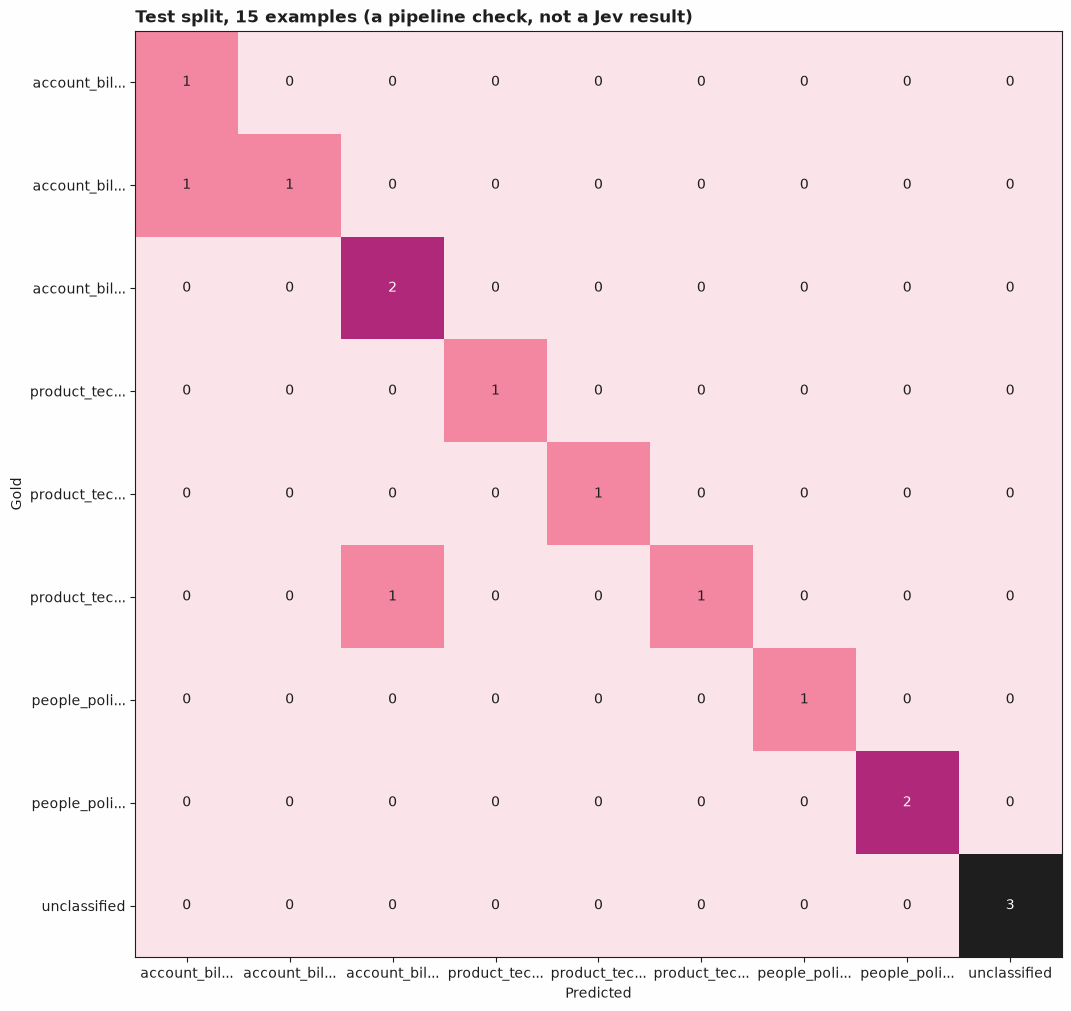

In [11]:
matrix = confusion_matrix(test_gold, branching_leaf, labels=list(helpers.FLAT_LEAVES))
width = max(len(label) for label in matrix.labels)
leader_width = max(width + len("gold "), len("predicted ->"))
header = "  ".join(f"{label:>{width}s}" for label in matrix.labels)
print(
    f"Test confusion matrix (hierarchical with branching), gold rows by predicted columns{check}:"
)
print(f"  {'predicted ->':<{leader_width}s}  {header}{check}")
for gold_label, row in zip(matrix.labels, matrix.matrix.tolist(), strict=True):
    counts = "  ".join(f"{count:{width}d}" for count in row)
    leader = f"gold {gold_label:<{width}s}"
    print(f"  {leader:<{leader_width}s}  {counts}{check}")
plot_confusion_matrix(matrix, title=f"Test split, {len(test_examples)} examples{check}")

In [12]:
action_log = ActionLog()
review_queue = ReviewQueue()
for example, _resolved, routing in zip(test_examples, test_resolved, test_routings, strict=True):
    if routing.outcome == helpers.ANSWERED:
        action_log.record(
            "file_document",
            {"doc_id": example.fields["doc_id"], "leaf": routing.leaf},
            rule=routing.reason,
        )
    else:
        review_queue.submit(
            {"doc_id": example.fields["doc_id"], "leaf": routing.leaf}, routing.reason
        )
print(f"filed automatically (ActionLog entries): {len(action_log.to_dicts())}{check}")
print(f"sent to review (ReviewQueue entries): {len(review_queue.pending())}{check}")

filed automatically (ActionLog entries): 14 (a pipeline check, not a Jev result)
sent to review (ReviewQueue entries): 1 (a pipeline check, not a Jev result)


In [13]:
print(
    "Test documents where the hierarchical policy, the greedy baseline, or the flat baseline "
    "disagreed with gold:"
)
for example, gold, resolved, greedy, flat_leaf in zip(
    test_examples, test_gold, test_resolved, greedy_leaf, test_flat, strict=True
):
    if resolved.leaf == gold and greedy == gold and flat_leaf == gold:
        continue
    print(
        f"  {example.id}: gold {gold} | branching {resolved.leaf} | greedy {greedy} | flat {flat_leaf}{check}"
    )

Test documents where the hierarchical policy, the greedy baseline, or the flat baseline disagreed with gold:
  t11-branch-rescue-shared-name: gold account_billing.general_question | branching account_billing.general_question | greedy product_technical.general_question | flat account_billing.general_question (a pipeline check, not a Jev result)
  t12-branch-rescue-second-department: gold people_policy.security_policy | branching people_policy.security_policy | greedy unclassified | flat people_policy.security_policy (a pipeline check, not a Jev result)
  t13-shared-name-trap: gold product_technical.general_question | branching account_billing.general_question | greedy account_billing.general_question | flat account_billing.general_question (a pipeline check, not a Jev result)
  t15-wrong-topic-right-department: gold account_billing.refund_request | branching account_billing.invoice_question | greedy account_billing.invoice_question | flat account_billing.invoice_question (a pipeline che

The cells above are why a single headline number is not enough for a hierarchy. `t11-branch-rescue-shared-name` and `t12-branch-rescue-second-department` are both cases where the department answer's own top choice, by raw probability, is wrong: the greedy baseline commits to it and misses, while branching explores the second-ranked real department too and wins on combined confidence -- the whole reason to carry more than one branch forward. `t13-shared-name-trap` is the opposite lesson: the department answer is confidently wrong, and the topic it settles on inside that wrong department happens to share its bare name with the correct answer's own topic, so a reader who compared bare topic names alone would call it right; comparing the full path calls it wrong, as it should be, and neither branching nor the flat baseline is immune to it. `t15-wrong-topic-right-department` is a third shape: the department answer is confidently *correct*, and the mistake is entirely inside it, at the topic stage -- exactly what department-level accuracy cannot see, and exactly why this section reports both levels rather than one.

Put plainly: on `test`, the flat classifier baseline matches this policy on both reported accuracies, at under half the request count. Leaf accuracy is 0.8667 for both the branching policy (33 requests) and the flat baseline (15 requests); department-level accuracy is 0.9333 for both, printed above for each; and both miss exactly the same two documents, `t13-shared-name-trap` and `t15-wrong-topic-right-department`. There is no quantity this notebook computes on which staging the question wins. What staging does not buy, on this taxonomy, is anything: `LEAVES_BY_DEPARTMENT` gives the three real departments 3, 3 and 2 topics of their own -- eight leaves in total, not a uniform count -- and the flat option list adds one more for the fallback: 8 + 1 = 9 options, `len(helpers.FLAT_LEAVES)`, small enough that one combined question is entirely practical to write and to answer, so there is no cost advantage left for two stages to recover. The staged design, by contrast, never asks a single question wider than the larger of the department question (the three real departments plus the fallback: 4) and the widest single department's own topic question (3, in account_billing or product_technical): `max(4, 3) = 4` against the flat question's 9 (`test_the_staged_policys_widest_question_is_smaller_than_the_flat_questions` and `test_the_real_leaf_count_is_eight_full_paths_plus_one_fallback` in `tests/test_helpers.py` pin all four numbers). The case for staging is a property of the taxonomy's *size*, not of this one. A *uniform* taxonomy of `D` departments with `T` topics each would put the flat count at `D * T + 1` and the staged width at `max(D + 1, T)` instead -- this taxonomy is not uniform, so substituting its own `D = 3` and largest `T = 3` into `D * T + 1` gives 10, not the 9 actually built, which is why the flat count above is read off `LEAVES_BY_DEPARTMENT` directly rather than from that formula. What the formula does show is the shape the gap takes as a taxonomy grows: a uniform taxonomy of ten departments of eight topics each would need an 81-option flat question against a staged design whose widest single question stays at 11 -- the shape in which staging starts to earn its keep. On this taxonomy it has not, and the honest report says so rather than quietly dropping the baseline that ties.

The review gate does not pay for itself on `test` either, and the sweep above already contains the proof: at `gate >= 0.2418`, the row just below the frozen `review_gate` of 0.2560, coverage is 1.0000 and risk is 0.1333, both better than the frozen gate's own 0.9333 and 0.1429. Ungated, every resolved path is reported and this split's coverage, accuracy and risk are 1.0000, 0.8667 and 0.1333; gated, they are 0.9333, 0.8571 and 0.1429 -- strictly worse on all three, not a trade. The one document the gate withholds is `t12-branch-rescue-second-department`, at path confidence 0.2418 against the frozen `review_gate` of 0.2560; the policy gets it right, so review removes a correct answer and gains nothing in exchange. A `validation`-only threshold does not know this in advance, and this recipe does not pretend it does: freezing a gate is a bet that confidence keeps separating right from wrong on data it has not seen, and this `test` split is exactly a case where that bet does not pay off.

## What was and was not measured

What this run can say about Jev depends on its mode, which the cell below states from `backend.mode`: a synthetic or scripted run is a pipeline check only, on the fixture sample it ran against; a recorded or live run states the model the API returned and when, for exactly the examples it covers. Nothing here says anything about Jev's quality, speed or cost unless that cell reports a recorded or live run. `N` below counts only the examples that carry a gold label, so it excludes the two `demo` documents shown earlier.

In [14]:
if offline:
    print(f"Provenance: {backend.mode}. Not measured live: a pipeline check, not a Jev result.")
    print(f"N: {len(val_examples)} validation and {len(test_examples)} test examples{check}")
else:
    dates = ", ".join(getattr(backend, "recorded_dates", ()) or ()) or "this run"
    print(f"Provenance: {backend.mode}, model {backend.model}")
    print(f"Captured: {dates}")
    print(f"N: {len(val_examples)} validation and {len(test_examples)} test examples")
print(f"total requests this notebook actually made: {_requests['n']}{check}")

Provenance: synthetic. Not measured live: a pipeline check, not a Jev result.
N: 14 validation and 15 test examples (a pipeline check, not a Jev result)
total requests this notebook actually made: 124 (a pipeline check, not a Jev result)


## Next steps

- Raise `branch_min_coverage` in "Python's part" above (0.65 to 0.90, say) and re-run from that section down: a tighter single-request floor can only move `branch_margin` down or leave it unchanged, since demanding that *more* validation documents clear the threshold only ever admits a *lower* threshold into the feasible set -- the opposite direction from raising it. The `test` split's own department confidences are bimodal: three documents sit at 0.0400, 0.1067 and 0.1467, and the rest cluster at 0.7867-0.8000, with nothing in between -- so any `branch_margin` that lands anywhere in that gap (everything in `(0.1467, 0.7867]`, which is where 0.85 lands) produces the identical branching set and changes nothing to watch. At 0.90, `branch_margin` drops below the low cluster: branching falls from three documents to one (`t14-genuinely-unclear` only), `branching_leaf` comes to agree with `greedy_leaf` on both documents where the two disagreed at the original floor (`t11-branch-rescue-shared-name` and `t12-branch-rescue-second-department`), and leaf accuracy on `test` falls from 0.8667 to 0.7333 -- branching was earning that accuracy on exactly the two documents it stops exploring at 0.90. The lesson is the gap itself: a threshold can move a long way through a confidence distribution's empty middle and change nothing, then flip everything the moment it crosses into the next cluster.
- Add a document to `ROWS` in `build_fixtures.py` whose department answer is confidently wrong and whose chosen topic happens to share a bare name with the correct topic in the right department (the shape `t13-shared-name-trap` already tests), run `python build_fixtures.py --force`, and confirm the full-path leaf accuracy falls while a bare-topic-name comparison alone would not have noticed.
- Neighbouring recipes: [`05-document-classification`](../05-document-classification/) (`Choice`), whose single-stage router this recipe extends into two stages, and [`38-abstention-and-review-queues`](../38-abstention-and-review-queues/) (`Choice`), whose confidence-gated review queue this recipe's `review_gate` reuses at the end of a longer pipeline.

A neighbour link above is a folder link, `../NN-slug/`, and that is the convention: `tools/render_catalog.py` builds the root README's catalog table from bare recipe titles with no per-row anchor, so a recipe cannot reliably link to another recipe's row there instead. Link only a neighbour whose `notebook.ipynb` is already committed on `main`: a folder link to one that is not yet published would 404 on GitHub, and a forward link like that is not allowed.